# MNIST MLP: chuyển từ Keras sang PyTorch rồi xuống dòng ghi: Mô hình 784 → 512 → 512 → 10 (ReLU, Dropout 0.2), SGD lr=0.01, batch 128, 30 epoch.

In [1]:
!pip -q install torchinfo

In [2]:
import os, time, random
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from google.colab import drive

drive.mount('/content/drive')
BASE = '/content/drive/MyDrive/BTL03'
os.makedirs(BASE + '/P1', exist_ok=True)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(torch.__version__, device)

Mounted at /content/drive
2.14.1+cpu cpu


In [3]:
tfm = transforms.ToTensor()          # chia 255, ảnh có dạng (1, 28, 28)
train_ds = datasets.MNIST('./data', train=True,  download=True, transform=tfm)
test_ds  = datasets.MNIST('./data', train=False, download=True, transform=tfm)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=128)
print(len(train_ds), len(test_ds))

100%|██████████| 9.91M/9.91M [00:00<00:00, 43.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.19MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.2MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.57MB/s]

60000 10000


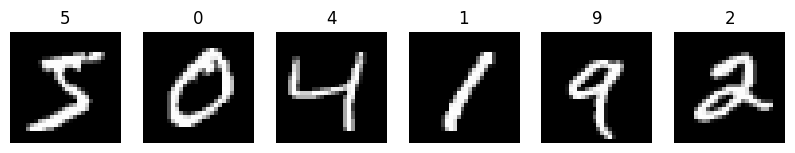

In [4]:
fig, ax = plt.subplots(1, 6, figsize=(10, 2))
for i in range(6):
    img, lab = train_ds[i]
    ax[i].imshow(img[0], cmap='gray'); ax[i].set_title(lab); ax[i].axis('off')
plt.show()

In [5]:
class MnistMLP(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 512)
        self.out = nn.Linear(512, num_classes)
        self.drop = nn.Dropout(0.2)

    def forward(self, x, return_features=False):
        x = self.flatten(x)
        x = self.drop(torch.relu(self.fc1(x)))
        f = torch.relu(self.fc2(x))              # đặc trưng của lớp fc2
        logits = self.out(self.drop(f))          # không có softmax ở cuối
        return (logits, f) if return_features else logits

model = MnistMLP().to(device)

from torchinfo import summary
summary(model, input_size=(1, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
MnistMLP                                 [1, 10]                   --
├─Flatten: 1-1                           [1, 784]                  --
├─Linear: 1-2                            [1, 512]                  401,920
├─Dropout: 1-3                           [1, 512]                  --
├─Linear: 1-4                            [1, 512]                  262,656
├─Dropout: 1-5                           [1, 512]                  --
├─Linear: 1-6                            [1, 10]                   5,130
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.67
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 2.68
Estimated Total Size (MB): 2.69

In [7]:
loss_fn = nn.CrossEntropyLoss()                       # nhận logits + nhãn số
opt = torch.optim.SGD(model.parameters(), lr=0.01)    # giống Keras: không momentum

def run_epoch(model, loader, opt=None):
    train = opt is not None
    model.train(train)                                # bật/tắt Dropout
    total, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = loss_fn(out, y)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total / n, correct / n

In [8]:
hist = {"loss": [], "acc": [], "val_loss": [], "val_acc": []}
t0 = time.time()
for ep in range(1, 31):
    l, a = run_epoch(model, train_loader, opt)
    vl, va = run_epoch(model, test_loader)
    for k, v in zip(hist, (l, a, vl, va)):
        hist[k].append(v)
    print(f"epoch {ep:2d} | loss {l:.4f} acc {a:.4f} | val_loss {vl:.4f} val_acc {va:.4f}")
train_time = time.time() - t0
print(f"Thời gian train: {train_time:.1f}s")

epoch  1 | loss 2.1144 acc 0.4975 | val_loss 1.6633 val_acc 0.7023
epoch  2 | loss 1.0862 acc 0.7562 | val_loss 0.6643 val_acc 0.8427
epoch  3 | loss 0.6084 acc 0.8356 | val_loss 0.4645 val_acc 0.8781
epoch  4 | loss 0.4844 acc 0.8627 | val_loss 0.3929 val_acc 0.8935
epoch  5 | loss 0.4277 acc 0.8785 | val_loss 0.3533 val_acc 0.9006
epoch  6 | loss 0.3914 acc 0.8883 | val_loss 0.3293 val_acc 0.9063
epoch  7 | loss 0.3671 acc 0.8942 | val_loss 0.3103 val_acc 0.9112
epoch  8 | loss 0.3469 acc 0.8999 | val_loss 0.2943 val_acc 0.9153
epoch  9 | loss 0.3292 acc 0.9049 | val_loss 0.2821 val_acc 0.9184
epoch 10 | loss 0.3128 acc 0.9097 | val_loss 0.2709 val_acc 0.9226
epoch 11 | loss 0.3013 acc 0.9127 | val_loss 0.2583 val_acc 0.9261
epoch 12 | loss 0.2881 acc 0.9159 | val_loss 0.2488 val_acc 0.9289
epoch 13 | loss 0.2780 acc 0.9203 | val_loss 0.2385 val_acc 0.9326
epoch 14 | loss 0.2668 acc 0.9234 | val_loss 0.2294 val_acc 0.9351
epoch 15 | loss 0.2584 acc 0.9255 | val_loss 0.2212 val_acc 0.

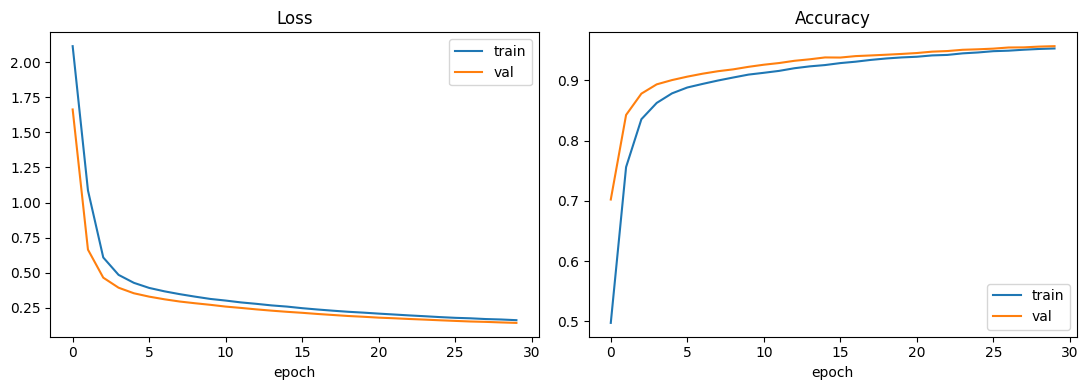

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(hist["acc"], label="train"); ax[1].plot(hist["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout()
plt.savefig(BASE + '/P1/mnist_mlp_curves.png', dpi=150)
plt.show()

In [11]:
test_loss, test_acc = run_epoch(model, test_loader)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 0.14217340581119062
Test accuracy: 0.9569


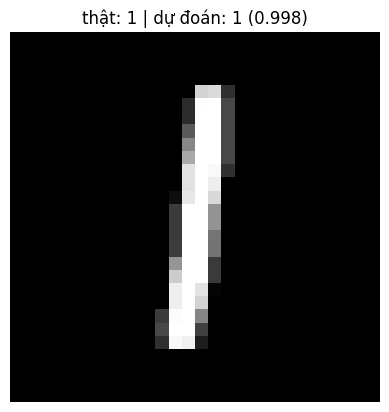

In [12]:
model.eval()
i = np.random.randint(len(test_ds))
img, label = test_ds[i]
with torch.no_grad():
    prob = torch.softmax(model(img.unsqueeze(0).to(device)), dim=1)[0].cpu()
plt.imshow(img[0], cmap='gray')
plt.title(f"thật: {label} | dự đoán: {prob.argmax().item()} ({prob.max():.3f})")
plt.axis('off'); plt.show()

In [13]:
feats = []
with torch.no_grad():
    for x, _ in test_loader:
        _, f = model(x.to(device), return_features=True)
        feats.append(f.cpu())
feats = torch.cat(feats)
print(feats.shape)

torch.Size([10000, 512])


In [14]:
torch.save(model.state_dict(), BASE + '/P1/mnist_mlp.pt')
print("Đã lưu")

Đã lưu
